# Сравнение рекомендательных моделей

Калинин Михаил, Б05-322

## Данные и запуск
Поля данных:

`user_id` - Идентификатор пользователя 

`parent_asin` - Идентификатор товара, объединяющий его варианты 

`rating` - Оценка от 1 до 5 

`timestamp` - Время отзыва

`verified_purchase` - Признак подтверждённой покупки 

Установите зависимости из `requirements.txt`, откройте ноутбук из папки проекта и выполните **Restart & Run All**. Например, в macOS/Linux:

```bash
python3 -m venv /tmp/recsys-env
source /tmp/recsys-env/bin/activate
python -m pip install -r requirements.txt
jupyter notebook experiments.ipynb
```

In [16]:
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import json
import platform
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import sparse
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

from models.item_knn import ItemKNN
from models.implicit_als import ImplicitALS
from models.ease import EASE
from models.fm import FM
from models.custom_als import CustomALS

SEED = 2026
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.precision', 6)

In [17]:
REVIEWS_URL = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/All_Beauty.jsonl'

def load_reviews(path=None):
    path = Path(path) if path is not None else Path(tempfile.gettempdir()) / 'recsys_top10_data' / 'All_Beauty.jsonl'
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists() or not path.stat().st_size:
        tmp = path.with_suffix('.jsonl.part')
        with requests.get(REVIEWS_URL, stream=True, timeout=(30,180)) as response:
            response.raise_for_status()
            with tmp.open('wb') as f:
                for chunk in response.iter_content(1024*1024):
                    f.write(chunk)
        tmp.replace(path)
    rows, malformed = [], 0
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for line in f:
            digest.update(line)
            if not line.strip():
                continue
            try:
                r = json.loads(line)
                rows.append({k:r.get(k) for k in ['user_id','parent_asin','rating','timestamp','verified_purchase']})
            except json.JSONDecodeError:
                malformed += 1
    raw = pd.DataFrame(rows).rename(columns={'parent_asin':'item_id'})
    return raw, {'sha256':digest.hexdigest(), 'malformed_lines':malformed, 'raw_rows':len(raw)}

raw, manifest = load_reviews()

## Очистка и исследование данных

Дубликаты user–item до очистки: 7599
После очистки: 693929 пользователей: 631986 товаров: 112565
Удалено: 7599


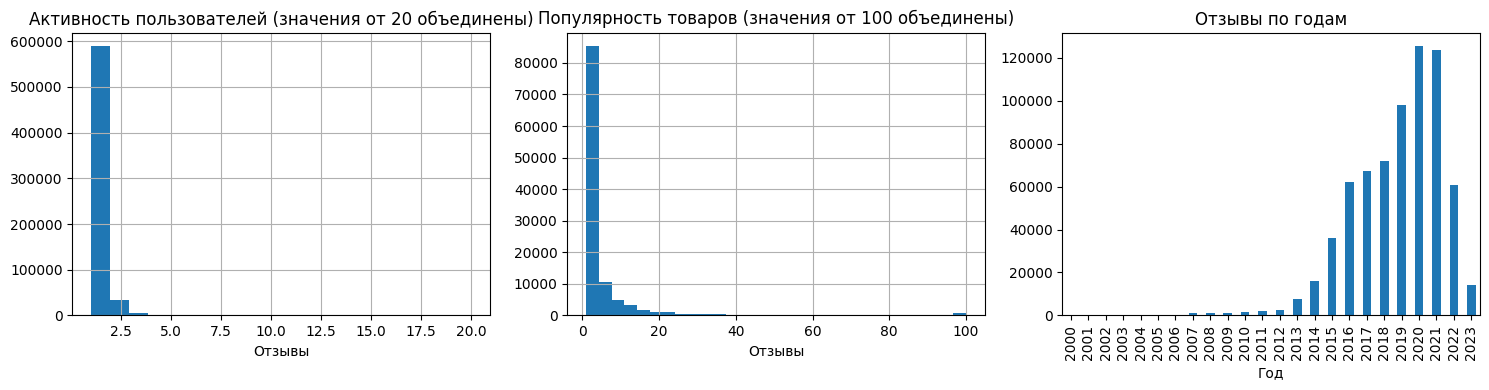

In [18]:
def clean_reviews(raw):
    events = raw.dropna(subset=['user_id','item_id','rating','timestamp']).copy()
    for col in ['user_id','item_id']:
        events[col] = events[col].astype(str).str.strip()
        events = events[events[col] != '']
    for col in ['rating','timestamp']:
        events[col] = pd.to_numeric(events[col], errors='coerce')
    events['timestamp'] = np.where(events.timestamp > 1e11, events.timestamp / 1000, events.timestamp)
    events = events[events.rating.between(1,5) & events.timestamp.between(631152000,2051222400)].copy()
    events['timestamp'] = events.timestamp.astype('int64')
    events['verified_purchase'] = events.verified_purchase.fillna(False).astype(bool)
    events = events.sort_values(['timestamp','user_id','item_id'], kind='stable')
    events = events.drop_duplicates(['user_id','item_id'], keep='first').reset_index(drop=True)
    events['datetime'] = pd.to_datetime(events.timestamp, unit='s', utc=True)
    return events

print('Дубликаты user–item до очистки:', raw.duplicated(['user_id','item_id']).sum())
events = clean_reviews(raw)
print('После очистки:', len(events), 'пользователей:', events.user_id.nunique(), 'товаров:', events.item_id.nunique())
print('Удалено:', len(raw)-len(events))
fig, axes = plt.subplots(1,3,figsize=(15,4))
events.groupby('user_id').size().clip(upper=20).hist(bins=20, ax=axes[0])
axes[0].set(title='Активность пользователей (значения от 20 объединены)', xlabel='Отзывы')
events.groupby('item_id').size().clip(upper=100).hist(bins=30, ax=axes[1])
axes[1].set(title='Популярность товаров (значения от 100 объединены)', xlabel='Отзывы')
events.datetime.dt.year.value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set(title='Отзывы по годам', xlabel='Год')
plt.tight_layout(); plt.show()

### Формирование выборки

In [19]:
def prepare(events, max_items=1000):
    t1, t2 = np.quantile(events.timestamp, [.7,.85]).astype('int64')
    early = events[events.timestamp < t1]
    counts = early.groupby('item_id').size().rename('count').reset_index()
    keep = counts.sort_values(['count','item_id'], ascending=[False,True]).head(max_items).item_id
    selected = events[events.item_id.isin(keep)].copy()
    user_map = {x:i for i,x in enumerate(sorted(selected.user_id.unique()))}
    item_map = {x:i for i,x in enumerate(sorted(keep))}
    selected['u'] = selected.user_id.map(user_map).astype('int32')
    selected['i'] = selected.item_id.map(item_map).astype('int32')
    train = selected[selected.timestamp < t1].copy()
    val = selected[(selected.timestamp >= t1)&(selected.timestamp < t2)].copy()
    test = selected[selected.timestamp >= t2].copy()
    assert 100000 <= len(selected) <= 2000000, f'Invalid interaction count: {len(selected)}'
    assert selected.u.nunique() >= 1000 and selected.i.nunique() >= 1000
    assert all(len(x) for x in [train,val,test])
    return selected, train, val, test, (len(user_map),len(item_map)), (int(t1),int(t2))

MAX_ITEMS = 1000
selected, train, validation, test, shape, cutoffs = prepare(events, MAX_ITEMS)

### Метапризнаки

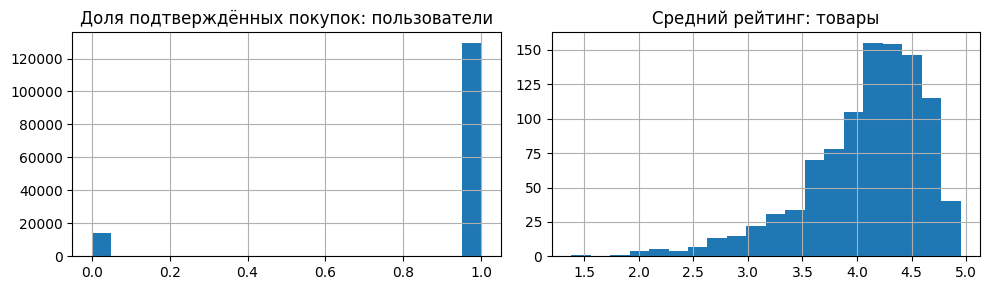

In [20]:
user_meta = train.groupby('u').agg(reviews=('rating','size'), mean_rating=('rating','mean'), verified_fraction=('verified_purchase','mean'))
item_meta = train.groupby('i').agg(reviews=('rating','size'), mean_rating=('rating','mean'), verified_fraction=('verified_purchase','mean'))
fig, axes = plt.subplots(1,2,figsize=(10,3))
user_meta.verified_fraction.hist(bins=20,ax=axes[0]); axes[0].set_title('Доля подтверждённых покупок: пользователи')
item_meta.mean_rating.hist(bins=20,ax=axes[1]); axes[1].set_title('Средний рейтинг: товары')
plt.tight_layout(); plt.show()

## Метрики
Метрики при $K=10$:

- **NDCG@10** учитывает позицию релевантного товара: $\mathrm{DCG}_u=\sum_{j=1}^{10}\mathrm{rel}_{uj}/\log_2(j+1)$, $\mathrm{NDCG}_u=\mathrm{DCG}_u/\mathrm{IDCG}_u$. Это основная метрика выбора параметров.
- **Recall@10** — доля релевантных товаров пользователя, найденных в списке: $|R_u^{10}\cap T_u|/|T_u|$.
- **Coverage@10** — доля каталога, рекомендованная хотя бы одному пользователю.

In [21]:
def topk_from_scores(scores, seen, candidates, k=10):
    scores = np.asarray(scores, dtype=float).copy()
    if not np.isfinite(scores).all():
        raise ValueError('Model returned non-finite scores')
    scores[:, ~candidates] = -np.inf
    r, c = seen.nonzero()
    scores[r, c] = -np.inf
    order = np.argsort(-scores, axis=1, kind='stable')[:, :k]
    return np.where(np.isfinite(np.take_along_axis(scores, order, axis=1)), order, -1)

def interaction_matrices(events, shape):
    seen = sparse.csr_matrix((np.ones(len(events)), (events.u, events.i)), shape=shape)
    e = events[events.rating >= 4]
    positive = sparse.csr_matrix((np.ones(len(e)), (e.u, e.i)), shape=shape)
    seen.data[:] = 1
    positive.data[:] = 1
    return seen, positive

def make_setup(history, holdout, shape):
    seen, positive = interaction_matrices(history, shape)
    candidates = np.asarray(seen.sum(axis=0)).ravel() > 0
    warm = np.asarray(positive.sum(axis=1)).ravel() > 0
    relevant = holdout[holdout.rating >= 4]
    available = relevant[candidates[relevant.i.to_numpy()] & warm[relevant.u.to_numpy()]]
    if len(available):
        unknown = np.asarray(seen[available.u.to_numpy(), available.i.to_numpy()]).ravel() == 0
        available = available[unknown]
    truth = available.groupby('u').i.agg(set).to_dict()
    users = np.array(sorted(truth), dtype=int)
    if not len(users):
        raise ValueError('No eligible evaluation users')
    return {'users': users, 'truth': truth, 'seen': seen, 'candidates': candidates,
            'coverage': len(available) / max(1,len(relevant)), 'shape': shape}

def evaluate(model, setup, k=10, batch_size=256):
    ndcg, recall, recommended = [], [], set()
    discount = 1 / np.log2(np.arange(2, k + 2))
    for start in range(0, len(setup['users']), batch_size):
        users = setup['users'][start:start+batch_size]
        recs = topk_from_scores(model.score(users), setup['seen'][users], setup['candidates'], k)
        for u, rec in zip(users, recs):
            truth = setup['truth'][int(u)]
            hits = np.array([int(i) in truth if i >= 0 else False for i in rec])
            ndcg.append(float(hits @ discount[:len(rec)]) / discount[:min(k,len(truth))].sum())
            recall.append(float(hits.sum()) / len(truth))
            recommended.update(int(i) for i in rec if i >= 0)
    return {f'ndcg@{k}': float(np.mean(ndcg)), f'recall@{k}': float(np.mean(recall)),
            f'coverage@{k}': len(recommended) / int(setup['candidates'].sum()),
            'eval_users': len(ndcg)}

val_setup = make_setup(train, validation, shape)

## Модели

### ItemKNN
Косинусное сходство товаров: $s_{ij}=X_i^TX_j/(\|X_i\|\|X_j\|)$
Диагональ равна нулю, для каждого исходного товара сохраняются ближайшие соседи
Предсказание: $\hat r_{ui}=\sum_jX_{uj}s_{ji}$

### iALS
$$L=\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X_f\|_F^2+\|Y_f\|_F^2)$$
где $p_{ui}=X_{ui}$, $c_{ui}=1+\alpha X_{ui}$

Факторы обновляются по очереди:
$$x_u=(Y_f^TY_f+Y_{I_u}^T(C_u-I)Y_{I_u}+\lambda I)^{-1}Y_{I_u}^TC_up_u$$

### EASE
$$\min_{\operatorname{diag}B=0}\|X-XB\|_F^2+\lambda\|B\|_F^2$$

### FM с метапризнаками
Для вектора признаков $z$:
$$f(z)=w_0+\sum_aw_az_a+\frac12\sum_f\left[(\sum_av_{af}z_a)^2-\sum_av_{af}^2z_a^2\right]$$

Обучение — логистическая функция потерь с L2-регуляризацией, собственные градиенты и Adam

### ALS с собственным целевым сигналом
Для обучающего положительного отзыва:
$$p^*_{ui}=\frac{r_{ui}-3}{2}\left[0.5+0.5\cdot2^{-\Delta t_{ui}/h}\right]$$
где $\Delta t_{ui}$ — возраст отзыва в днях относительно последнего события обучающей истории, $h$ — период полураспада

In [22]:
PRIMARY = 'ndcg@10'

SEARCH = {
    'ItemKNN': [{'neighbors':20}, {'neighbors':80}],
    'ImplicitALS': [{'factors':16,'reg':1.}, {'factors':16,'reg':10.}],
    'EASE': [{'regularization':100.}, {'regularization':1000.}],
    'FM': [{'factors':8,'lr':.005}, {'factors':8,'lr':.02}],
    'CustomALS': [{'factors':16,'reg':r,'half_life_days':d} for r in [1.,10.] for d in [180,730]],
}

CLASSES = {'ItemKNN':ItemKNN,'ImplicitALS':ImplicitALS,'EASE':EASE,'FM':FM,'CustomALS':CustomALS}

def fit_model(name, params, positive, history):
    model = CLASSES[name](**params)
    if name in ['FM','CustomALS']:
        return model.fit(positive, history)
    return model.fit(positive)

def tune(train, validation, shape):
    _, positive = interaction_matrices(train, shape)
    setup = make_setup(train, validation, shape)
    rows, best = [], {}
    total = sum(map(len,SEARCH.values()))
    for name, grid in SEARCH.items():
        best_score = -1
        for params in grid:
            start = time.perf_counter()
            model = fit_model(name, params, positive, train)
            fit_seconds = time.perf_counter()-start
            metrics = evaluate(model, setup)
            rows.append({'model':name,'params':json.dumps(params,sort_keys=True),**metrics,
                         'fit_seconds':fit_seconds,'total_seconds':time.perf_counter()-start})
            print(f"  NDCG@10={metrics[PRIMARY]:.6f}; {rows[-1]['total_seconds']:.1f} s", flush=True)
            if metrics[PRIMARY] > best_score:
                best_score, best[name] = metrics[PRIMARY], dict(params)
            del model
            gc.collect()
    return pd.DataFrame(rows), best

display(pd.DataFrame([{'model': name, 'params': json.dumps(params)}
                      for name, grid in SEARCH.items() for params in grid]))
validation_results, best_params = tune(train, validation, shape)

,model,params
0,ItemKNN,"{""neighbors"": 20}"
1,ItemKNN,"{""neighbors"": 80}"
2,ImplicitALS,"{""factors"": 16, ""reg"": 1.0}"
3,ImplicitALS,"{""factors"": 16, ""reg"": 10.0}"
4,EASE,"{""regularization"": 100.0}"
5,EASE,"{""regularization"": 1000.0}"
6,FM,"{""factors"": 8, ""lr"": 0.005}"
7,FM,"{""factors"": 8, ""lr"": 0.02}"
8,CustomALS,"{""factors"": 16, ""reg"": 1.0, ""half_life_days"": ..."
9,CustomALS,"{""factors"": 16, ""reg"": 1.0, ""half_life_days"": ..."


  NDCG@10=0.038010; 0.0 s
  NDCG@10=0.038010; 0.0 s
  NDCG@10=0.030505; 2.4 s
  NDCG@10=0.034241; 2.4 s
  NDCG@10=0.044307; 0.0 s
  NDCG@10=0.044307; 0.0 s
  NDCG@10=0.045717; 2.2 s
  NDCG@10=0.046160; 2.2 s
  NDCG@10=0.036721; 2.4 s
  NDCG@10=0.039267; 2.4 s
  NDCG@10=0.039038; 2.4 s
  NDCG@10=0.036579; 2.4 s


## 5. Результаты на test
Модели с выбранными параметрами переобучаются на train+validation. В таблице приведены метрики, параметры и время обучения. `total_seconds` также включает оценку.

,model,params,ndcg@10,recall@10,coverage@10,eval_users,fit_seconds,total_seconds
0,FM_ID_only,"{""factors"": 8, ""lr"": 0.02, ""use_metadata"": false}",0.027633,0.057143,0.023,70,2.001325,2.003918
1,EASE,"{""regularization"": 100.0}",0.027428,0.042857,0.363,70,0.017641,0.020319
2,CustomALS,"{""factors"": 16, ""half_life_days"": 730, ""reg"": ...",0.026771,0.057143,0.190,70,2.582121,2.584873
3,ImplicitALS,"{""factors"": 16, ""reg"": 10.0}",0.022702,0.057143,0.192,70,2.547212,2.549949
4,ItemKNN,"{""neighbors"": 20}",0.020438,0.028571,0.297,70,0.013382,0.014266
5,ALS_matched_custom,"{""factors"": 16, ""reg"": 1.0}",0.017205,0.042857,0.200,70,2.591863,2.594583
6,FM,"{""factors"": 8, ""lr"": 0.02}",0.004507,0.014286,0.038,70,2.174477,2.177350


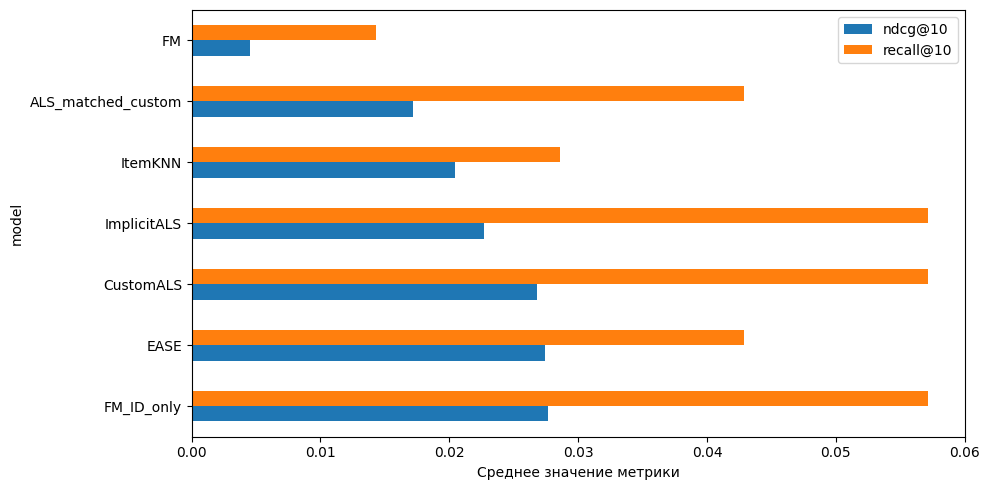

In [23]:
def final_comparison(train, validation, test, shape, best):
    history = pd.concat([train,validation],ignore_index=True)
    _, positive = interaction_matrices(history,shape)
    setup = make_setup(history,test,shape)
    rows = []
    configs = [(name,p) for name,p in best.items()]
    configs += [('FM_ID_only',{**best['FM'],'use_metadata':False}),
                ('ALS_matched_custom',{k:v for k,v in best['CustomALS'].items() if k!='half_life_days'})]
    for name, params in configs:
        base = {'FM_ID_only':'FM','ALS_matched_custom':'ImplicitALS'}.get(name,name)
        start = time.perf_counter()
        model = fit_model(base,params,positive,history)
        fit_seconds = time.perf_counter()-start
        rows.append({'model':name,'params':json.dumps(params,sort_keys=True),**evaluate(model,setup),
                     'fit_seconds':fit_seconds,'total_seconds':time.perf_counter()-start})
        del model
        gc.collect()
    result = pd.DataFrame(rows).sort_values(PRIMARY,ascending=False).reset_index(drop=True)
    return result, setup

results, test_setup = final_comparison(train,validation,test,shape,best_params)
original_test_positive = ((events.timestamp >= cutoffs[1]) & (events.rating >= 4)).sum()
selected_test_positive = (test.rating >= 4).sum()
display(results)
ax = results.set_index('model')[['ndcg@10','recall@10']].plot.barh(figsize=(10,5))
ax.set_xlabel('Среднее значение метрики'); plt.tight_layout(); plt.show()

## 6. Выводы

Среди пяти основных моделей наибольший test NDCG@10 получил **EASE**:
**0.027428**, Recall@10 — **0.042857**. Выбранные параметры: `{"regularization": 100.0}`.

Метапризнаки FM снизили NDCG@10 на **0.023127** относительно FM только на ID.
Кастомный сигнал ALS повысил NDCG@10 на **0.004069** относительно базового iALS с выбранными на validation настройками.
При совпадающих настройках ALS изменение составило **+0.009566**.